# EN3160 Assignment 03

## Neural Network

---

**Name:** R.A.C.D. Ranawaka    
**Index Number:** 230526A  
**GitHub Link:** https://github.com/chaniruranawaka/Neural-Network

---

## Question 1 - Manually trained dense network on CIFAR-10

In [38]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [39]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

print("Training images:", len(trainset))
print("Testing images:", len(testset))

Training images: 50000
Testing images: 10000


### (a) Add a 100-unit sigmoid hidden layer

The following cell defines the input, hidden, and output parameters. The hidden layer uses the sigmoid activation.

In [40]:
# 2. Define Network Parameters
Din = 3 * 32 * 32   # Input size (flattened CIFAR-10 image size)
H = 100             # Middle layer with 100 nodes
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
epochs = 10
lr = 0.1
lr_decay = 0.9
reg = 0
loss_history = []
epoch_losses = []

print("w1 shape:", w1.shape)
print("b1 shape:", b1.shape)
print("w2 shape:", w2.shape)
print("b2 shape:", b2.shape)

w1 shape: torch.Size([3072, 100])
b1 shape: torch.Size([100])
w2 shape: torch.Size([100, 10])
b2 shape: torch.Size([10])


### (b) Use cross-entropy loss

The training loop uses the cross-entropy loss on output logits and manually computes its gradients for backpropagation.

In [41]:
# 3. Training Loop
for t in range(epochs):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_pred = h1.mm(w2) + b2

        # Cross-entropy loss
        loss = nn.functional.cross_entropy(y_pred, labels) + reg * (
            torch.sum(w1 * w1) + torch.sum(w2 * w2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        probs = torch.softmax(y_pred, dim=1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        dy_pred = (probs - y_train_onehot) / Ntr

        dw2 = h1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        dh1 = dy_pred.mm(w2.t())
        dz1 = dh1 * h1 * (1 - h1)

        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    epoch_loss = running_loss / len(trainloader)
    epoch_losses.append(epoch_loss)

    print(f"Epoch {t + 1}/{epochs}, Loss: {epoch_loss:.4f}")

    # Learning rate decay
    lr *= lr_decay

Epoch 1/10, Loss: 2.0335
Epoch 2/10, Loss: 1.7789
Epoch 3/10, Loss: 1.6990
Epoch 4/10, Loss: 1.6474
Epoch 5/10, Loss: 1.6066
Epoch 6/10, Loss: 1.5708
Epoch 7/10, Loss: 1.5405
Epoch 8/10, Loss: 1.5126
Epoch 9/10, Loss: 1.4894
Epoch 10/10, Loss: 1.4667


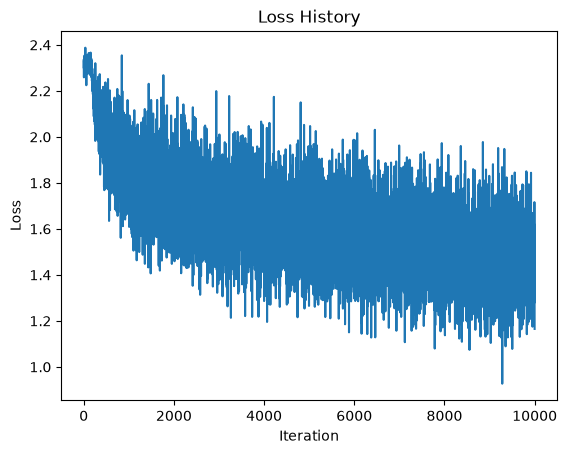

In [42]:
# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

### (c) Report accuracy after 10 epochs

The following cells calculate final accuracy on the training and test sets.

In [43]:
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_train_pred = h1.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 50.52%


In [44]:
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        z1 = x_test.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_test_pred = h1.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 47.38%


### Question 1 discussion

After 10 epochs, the manually trained network reached **50.52% training accuracy** and **47.38% test accuracy**. The training loss decreased from **2.0335** in epoch 1 to **1.4667** in epoch 10, showing that the network learned useful class distinctions. The 3.06 percentage-point train-test gap suggests some generalization loss, while the overall accuracy remains modest. This is expected for a small fully connected model because flattening CIFAR-10 images removes their spatial layout.

## Question 2 - CNN models for MNIST

The LeNet-5 model and the modern CNN use the same MNIST training and test splits. Both are trained for 10 epochs with cross-entropy loss. Each model's epoch output reports training and test loss and accuracy. The test set is reserved for evaluation.

In [45]:
import copy
import numpy as np
from torch.utils.data import DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
mnist_train = torchvision.datasets.MNIST(
    "./data", train=True, download=True, transform=mnist_transform
)
mnist_test = torchvision.datasets.MNIST(
    "./data", train=False, download=True, transform=mnist_transform
)
mnist_trainloader = DataLoader(
    mnist_train, batch_size=128, shuffle=True, num_workers=0,
    pin_memory=(device.type == "cuda")
)
mnist_testloader = DataLoader(
    mnist_test, batch_size=256, shuffle=False, num_workers=0,
    pin_memory=(device.type == "cuda")
)
mnist_classes = [str(i) for i in range(10)]
mnist_epochs = 10

Device: cpu


### Model definitions and shared evaluation helpers

The code below defines LeNet-5 and the three-convolution CNN, along with common training, plotting, and confusion-matrix functions.

In [46]:
class LeNet5(nn.Module):
    """LeNet-5 style classifier for 28x28 MNIST images."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 4 * 4, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10)
        )
    def forward(self, x):
        return self.classifier(self.features(x))


class SmallCNN(nn.Module):
    """Three convolution layers with batch normalization and dropout."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.10),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.15),
            nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.30), nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x))


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = 0.0
    correct = 0
    count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            batch_count = labels.size(0)
            loss_sum += loss.item() * batch_count
            correct += (logits.argmax(1) == labels).sum().item()
            count += batch_count
    return loss_sum / count, 100.0 * correct / count


def fit_classifier(model, trainloader, testloader, epochs, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(model, trainloader, criterion, optimizer)
        test_loss, test_acc = run_epoch(model, testloader, criterion)
        for key, value in zip(history, (train_loss, train_acc, test_loss, test_acc)):
            history[key].append(value)
        print(f"Epoch {epoch + 1:02d}/{epochs}: train loss {train_loss:.4f}, train acc {train_acc:.2f}% | test loss {test_loss:.4f}, test acc {test_acc:.2f}%")
    return model, history


def plot_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs, history["test_loss"], marker="o", label="Test")
    axes[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
    axes[1].plot(epochs, history["test_acc"], marker="o", label="Test")
    axes[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()


def get_confusion_matrix(model, loader, num_classes=10):
    matrix = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            predictions = model(images.to(device)).argmax(1).cpu()
            ids = labels * num_classes + predictions
            matrix += torch.bincount(ids, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return matrix.numpy()


def show_confusion_matrix(matrix, class_names, title):
    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(matrix, cmap="Blues")
    ax.set(title=title, xlabel="Predicted label", ylabel="True label")
    ax.set_xticks(range(len(class_names)), class_names, rotation=45)
    ax.set_yticks(range(len(class_names)), class_names)
    fig.colorbar(image, ax=ax, label="Number of images")
    threshold = matrix.max() / 2
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            ax.text(col, row, str(matrix[row, col]), ha="center", va="center",
                    color="white" if matrix[row, col] > threshold else "black", fontsize=8)
    plt.tight_layout(); plt.show()

### (a) Train LeNet-5 for 10 epochs

In [47]:
lenet_model, lenet_history = fit_classifier(
    LeNet5(), mnist_trainloader, mnist_testloader, mnist_epochs
)
print(
    f"LeNet-5 final: train accuracy = {lenet_history['train_acc'][-1]:.2f}%, "
    f"test accuracy = {lenet_history['test_acc'][-1]:.2f}%"
)

Epoch 01/10: train loss 0.3438, train acc 90.61% | test loss 0.1035, test acc 97.03%
Epoch 02/10: train loss 0.0854, train acc 97.40% | test loss 0.0567, test acc 98.18%
Epoch 03/10: train loss 0.0566, train acc 98.28% | test loss 0.0465, test acc 98.55%
Epoch 04/10: train loss 0.0447, train acc 98.64% | test loss 0.0430, test acc 98.44%
Epoch 05/10: train loss 0.0377, train acc 98.82% | test loss 0.0433, test acc 98.55%
Epoch 06/10: train loss 0.0320, train acc 99.03% | test loss 0.0410, test acc 98.65%
Epoch 07/10: train loss 0.0261, train acc 99.19% | test loss 0.0386, test acc 98.77%
Epoch 08/10: train loss 0.0237, train acc 99.28% | test loss 0.0343, test acc 98.85%
Epoch 09/10: train loss 0.0195, train acc 99.38% | test loss 0.0419, test acc 98.64%
Epoch 10/10: train loss 0.0175, train acc 99.44% | test loss 0.0395, test acc 98.82%
LeNet-5 final: train accuracy = 99.44%, test accuracy = 98.82%


### (b) Train the modern three-layer CNN for 10 epochs

In [48]:
smallcnn_model, smallcnn_history = fit_classifier(
    SmallCNN(), mnist_trainloader, mnist_testloader, mnist_epochs
)
print(
    f"Three-layer CNN final: train accuracy = {smallcnn_history['train_acc'][-1]:.2f}%, "
    f"test accuracy = {smallcnn_history['test_acc'][-1]:.2f}%"
)

Epoch 01/10: train loss 0.8835, train acc 74.85% | test loss 0.2162, test acc 96.00%
Epoch 02/10: train loss 0.2472, train acc 93.54% | test loss 0.1031, test acc 97.42%
Epoch 03/10: train loss 0.1577, train acc 95.71% | test loss 0.0636, test acc 98.42%
Epoch 04/10: train loss 0.1190, train acc 96.62% | test loss 0.0540, test acc 98.52%
Epoch 05/10: train loss 0.1039, train acc 96.97% | test loss 0.0449, test acc 98.69%
Epoch 06/10: train loss 0.0949, train acc 97.15% | test loss 0.0400, test acc 98.89%
Epoch 07/10: train loss 0.0826, train acc 97.54% | test loss 0.0379, test acc 98.93%
Epoch 08/10: train loss 0.0779, train acc 97.66% | test loss 0.0343, test acc 99.03%
Epoch 09/10: train loss 0.0695, train acc 97.90% | test loss 0.0322, test acc 99.00%
Epoch 10/10: train loss 0.0657, train acc 97.97% | test loss 0.0321, test acc 98.99%
Three-layer CNN final: train accuracy = 97.97%, test accuracy = 98.99%


### (c) Plot epoch metrics and show test confusion matrices

The plots below show training and test loss and accuracy for both models. Each confusion matrix is computed on the held-out MNIST test set.

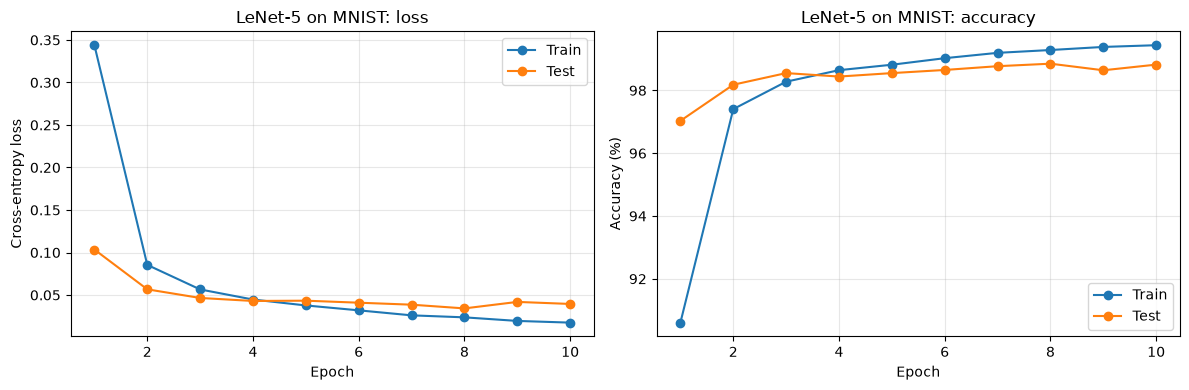

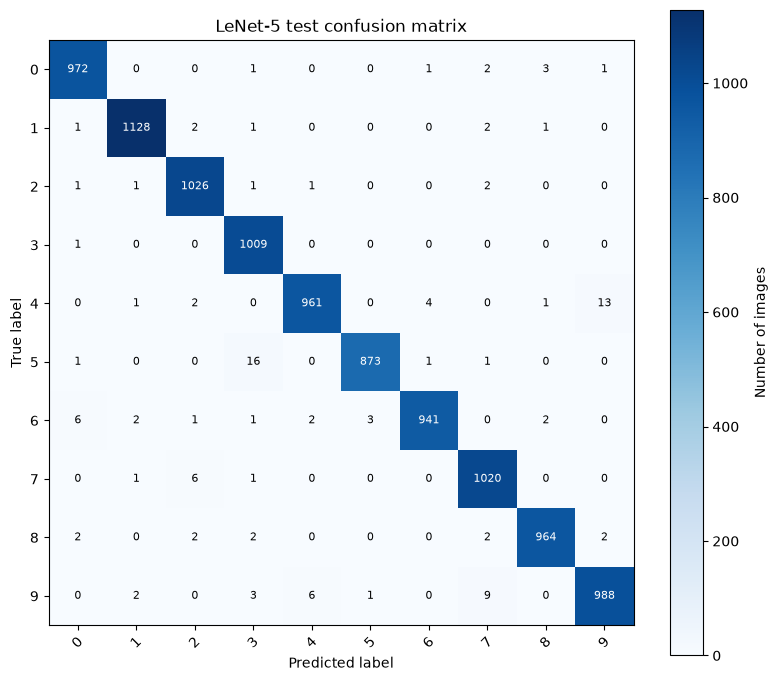

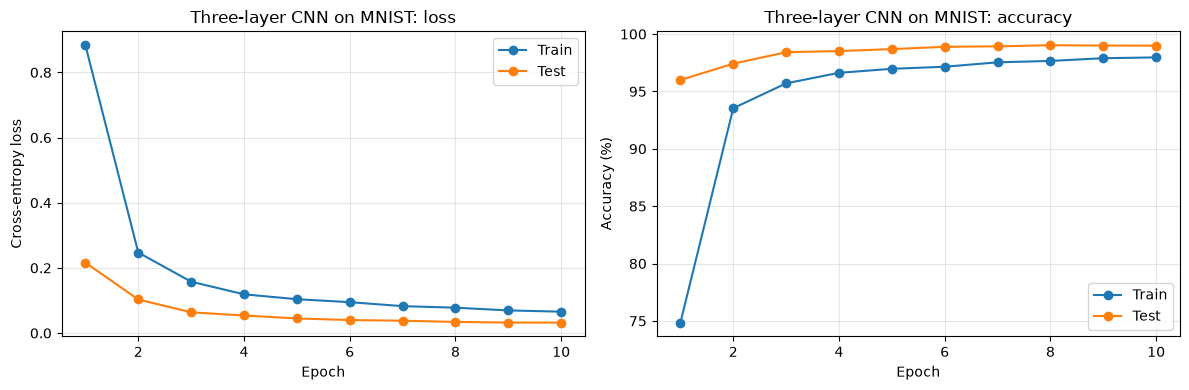

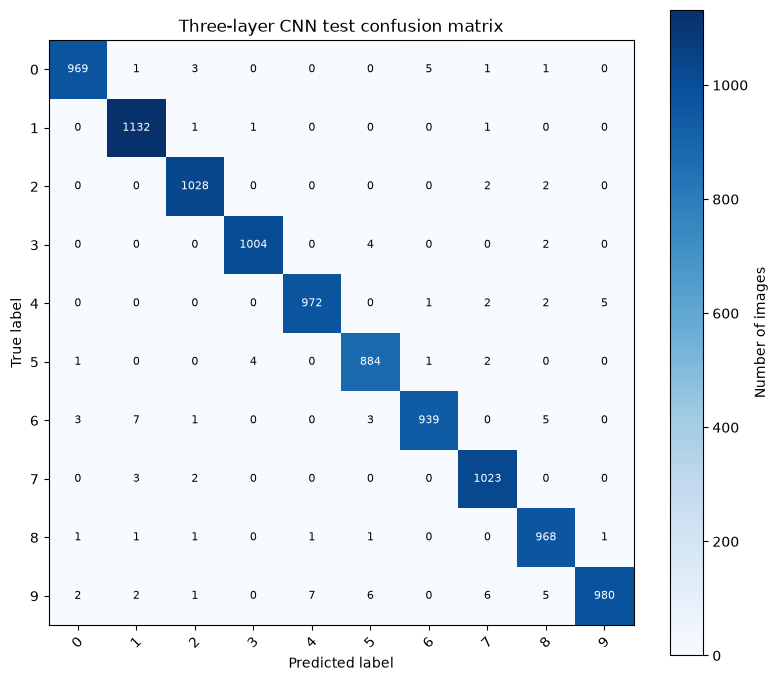

In [49]:
plot_history(lenet_history, "LeNet-5 on MNIST")
lenet_cm = get_confusion_matrix(lenet_model, mnist_testloader)
show_confusion_matrix(lenet_cm, mnist_classes, "LeNet-5 test confusion matrix")

plot_history(smallcnn_history, "Three-layer CNN on MNIST")
smallcnn_cm = get_confusion_matrix(smallcnn_model, mnist_testloader)
show_confusion_matrix(smallcnn_cm, mnist_classes, "Three-layer CNN test confusion matrix")

### Question 2 discussion

After 10 epochs, **LeNet-5** reached **99.44% training accuracy** and **98.82% test accuracy**, with a final test loss of **0.0395**. The **three-layer CNN** reached **97.97% training accuracy** and **98.99% test accuracy**, with a final test loss of **0.0321**. The modern CNN improved test accuracy by 0.17 percentage points and had the lower final test loss.

The modern CNN's lower reported training accuracy is consistent with dropout being active during training; its training batches are also scored while the weights are still being updated. The test accuracies are evaluated with dropout disabled, so the training and test accuracy values are not directly comparable for this model. Both models perform strongly on MNIST. In each confusion matrix, inspect off-diagonal counts to see which digits are confused. The plots show the loss and accuracy trends over all 10 epochs.

## Question 3 - Transfer learning with ImageNet-pretrained ResNet-18

This section follows the [PyTorch transfer learning tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) and uses its Hymenoptera ants-and-bees dataset. Both approaches start from ImageNet-1K pretrained weights and use the same data split and image transforms. Validation accuracy and loss are reported by epoch.

In [50]:
import urllib.request
import urllib.error
import zipfile
from pathlib import Path
from torchvision import models

data_root = Path("./data/hymenoptera_data")
archive = Path("./data/hymenoptera_data.zip")
dataset_ready = all((data_root / split).is_dir() for split in ("train", "val"))

if not dataset_ready:
    archive.parent.mkdir(parents=True, exist_ok=True)
    if not archive.exists():
        try:
            urllib.request.urlretrieve(
                "https://download.pytorch.org/tutorial/hymenoptera_data.zip", archive
            )
        except urllib.error.URLError as exc:
            raise RuntimeError(
                "Could not download the Hymenoptera dataset. The error indicates "
                "that this environment cannot resolve/reach download.pytorch.org. "
                "Connect to the internet and rerun this cell, or download "
                "hymenoptera_data.zip manually and place it in ./data/. Then rerun."
            ) from exc
    with zipfile.ZipFile(archive, "r") as zip_ref:
        zip_ref.extractall(archive.parent)

missing_splits = [split for split in ("train", "val") if not (data_root / split).is_dir()]
if missing_splits:
    raise FileNotFoundError(
        f"Dataset folders missing: {missing_splits}. Expected ./data/hymenoptera_data/ "
        "to contain train/ and val/ folders."
    )

data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
        transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    "val": transforms.Compose([
        transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}
image_datasets = {
    split: torchvision.datasets.ImageFolder(data_root / split, data_transforms[split])
    for split in ("train", "val")
}
image_loaders = {
    split: DataLoader(image_datasets[split], batch_size=8, shuffle=(split == "train"),
                      num_workers=0, pin_memory=(device.type == "cuda"))
    for split in ("train", "val")
}
class_names = image_datasets["train"].classes
dataset_sizes = {split: len(image_datasets[split]) for split in image_datasets}
print("Classes:", class_names, "| split sizes:", dataset_sizes)

Classes: ['ants', 'bees'] | split sizes: {'train': 244, 'val': 153}


In [51]:
def make_resnet18(feature_extraction=False):
    # DEFAULT selects the current torchvision ImageNet-1K pretrained weights.
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if feature_extraction:
        for parameter in model.parameters():
            parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    return model.to(device)


def train_transfer_model(model, trainable_parameters, epochs=10, lr=1e-3, freeze_backbone=False):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(trainable_parameters, lr=lr, momentum=0.9)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_weights = copy.deepcopy(model.state_dict())
    best_val = 0.0
    for epoch in range(epochs):
        for split in ("train", "val"):
            training = split == "train"
            model.train(training)
            if training and freeze_backbone:
                model.eval()
                model.fc.train()
            loss_sum = 0.0
            correct = 0
            count = 0
            context = torch.enable_grad() if training else torch.no_grad()
            with context:
                for images, labels in image_loaders[split]:
                    images, labels = images.to(device), labels.to(device)
                    if training:
                        optimizer.zero_grad(set_to_none=True)
                    logits = model(images)
                    loss = criterion(logits, labels)
                    if training:
                        loss.backward()
                        optimizer.step()
                    n = labels.size(0)
                    loss_sum += loss.item() * n
                    correct += (logits.argmax(1) == labels).sum().item()
                    count += n
            epoch_loss = loss_sum / count
            epoch_acc = 100.0 * correct / count
            history[f"{split}_loss"].append(epoch_loss)
            history[f"{split}_acc"].append(epoch_acc)
            if split == "val" and epoch_acc > best_val:
                best_val = epoch_acc
                best_weights = copy.deepcopy(model.state_dict())
        scheduler.step()
        print(f"Epoch {epoch + 1:02d}/{epochs}: train loss {history['train_loss'][-1]:.4f}, train acc {history['train_acc'][-1]:.2f}% | val loss {history['val_loss'][-1]:.4f}, val acc {history['val_acc'][-1]:.2f}%")
    model.load_state_dict(best_weights)
    return model, history, best_val


def plot_transfer_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
    axes[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss"); axes[0].legend(); axes[0].grid(True, alpha=.3)
    axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
    axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation")
    axes[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy (%)"); axes[1].legend(); axes[1].grid(True, alpha=.3)
    plt.tight_layout(); plt.show()

### (a) Fine tune the pretrained ResNet-18

All ResNet-18 parameters, including the replacement two-class output layer, are trainable.

Epoch 01/10: train loss 0.5605, train acc 68.44% | val loss 0.2478, val acc 92.81%
Epoch 02/10: train loss 0.3924, train acc 83.20% | val loss 0.2215, val acc 92.81%
Epoch 03/10: train loss 0.5711, train acc 78.69% | val loss 0.2398, val acc 90.20%
Epoch 04/10: train loss 0.2550, train acc 87.30% | val loss 0.2278, val acc 93.46%
Epoch 05/10: train loss 0.2591, train acc 89.75% | val loss 0.2865, val acc 93.46%
Epoch 06/10: train loss 0.3134, train acc 87.70% | val loss 0.3248, val acc 89.54%
Epoch 07/10: train loss 0.1824, train acc 94.26% | val loss 0.2610, val acc 94.77%
Epoch 08/10: train loss 0.2423, train acc 92.62% | val loss 0.2648, val acc 93.46%
Epoch 09/10: train loss 0.2052, train acc 90.57% | val loss 0.2803, val acc 92.81%
Epoch 10/10: train loss 0.2237, train acc 92.21% | val loss 0.2574, val acc 94.77%


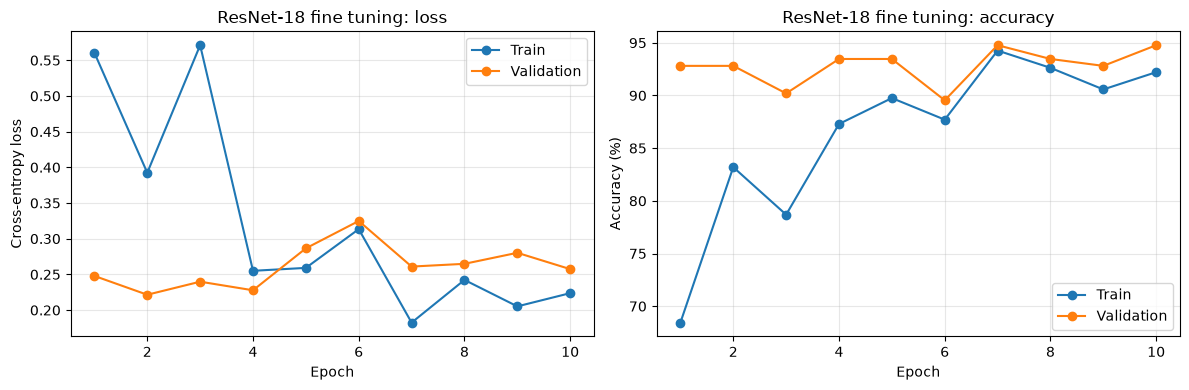

Fine tuning: best validation accuracy = 94.77%


In [52]:
finetune_model = make_resnet18(feature_extraction=False)
finetune_model, finetune_history, finetune_best_val = train_transfer_model(
    finetune_model, finetune_model.parameters(), epochs=10, lr=1e-3
)
plot_transfer_history(finetune_history, "ResNet-18 fine tuning")
print(f"Fine tuning: best validation accuracy = {finetune_best_val:.2f}%")

### (b) Use ResNet-18 as a fixed feature extractor

The pretrained backbone remains frozen, including its batch-normalization statistics. Only the new output layer is trained.

Epoch 01/10: train loss 0.4344, train acc 76.64% | val loss 0.1595, val acc 95.42%
Epoch 02/10: train loss 0.1826, train acc 93.03% | val loss 0.1501, val acc 95.42%
Epoch 03/10: train loss 0.1683, train acc 93.85% | val loss 0.1418, val acc 95.42%
Epoch 04/10: train loss 0.1398, train acc 94.26% | val loss 0.1370, val acc 96.08%
Epoch 05/10: train loss 0.1196, train acc 94.67% | val loss 0.1337, val acc 96.08%
Epoch 06/10: train loss 0.1508, train acc 93.85% | val loss 0.1347, val acc 96.08%
Epoch 07/10: train loss 0.1062, train acc 97.54% | val loss 0.1298, val acc 96.08%
Epoch 08/10: train loss 0.1081, train acc 95.49% | val loss 0.1313, val acc 96.08%
Epoch 09/10: train loss 0.0883, train acc 96.72% | val loss 0.1325, val acc 96.08%
Epoch 10/10: train loss 0.1278, train acc 94.26% | val loss 0.1334, val acc 96.08%


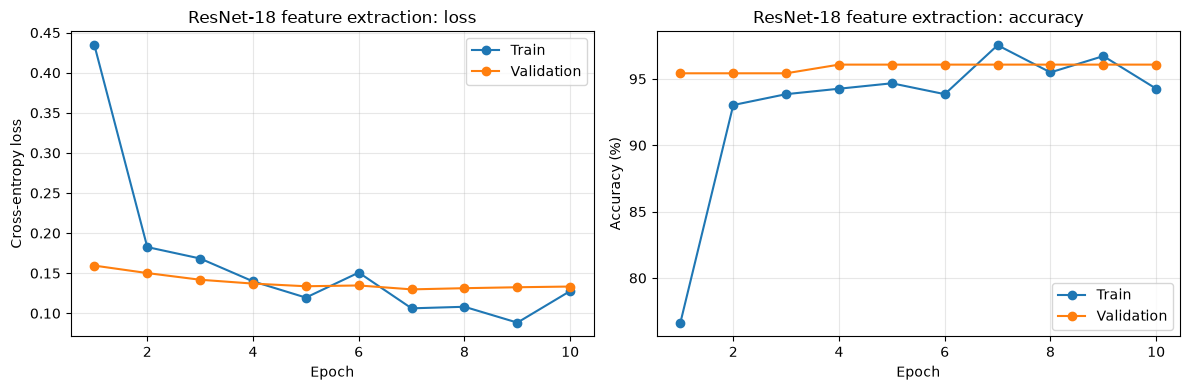

Feature extraction: best validation accuracy = 96.08%


In [53]:
feature_model = make_resnet18(feature_extraction=True)
feature_model, feature_history, feature_best_val = train_transfer_model(
    feature_model, feature_model.fc.parameters(), epochs=10, lr=1e-3, freeze_backbone=True
)
plot_transfer_history(feature_history, "ResNet-18 feature extraction")
print(f"Feature extraction: best validation accuracy = {feature_best_val:.2f}%")

### Question 3 discussion

After 10 epochs, fine tuning reached a best validation accuracy of **94.77%**, while feature extraction reached **96.08%**. On the 153-image validation set, these correspond to 145 and 147 correct predictions, respectively: feature extraction classified two more images correctly in this run. Its best validation accuracy was sustained from epoch 4 through epoch 10, while fine tuning's best value, 94.77%, occurred at epochs 7 and 10.

The loss curves show different behavior. Fine tuning's lowest validation loss was **0.2215** at epoch 2, then it fluctuated and ended at **0.2574**. Feature extraction's validation loss fell to **0.1298** at epoch 7 and ended at **0.1334**. For this run, keeping the ImageNet backbone fixed gave slightly better and more stable validation results than updating all its weights. The dataset is small, and the accuracy difference is only two images, so this result alone does not show that feature extraction will always be better.

Training accuracy is measured while the model is in training mode and the training images are randomly augmented; validation uses deterministic transforms. The training and validation accuracy values therefore are not directly comparable. These are **validation** results from the Hymenoptera split, not test-set results.